# Population PCA

Fit axes of genetic variation on simulated training individuals and project independent individuals onto those same axes.

The allele frequencies, centring and scale are estimated from training genotypes only. The usual biallelic scale is the square root of 2p(1−p). Each point represents an artificial observation, and the groups below exist only in the simulation.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

## Worked example

Run the example from top to bottom. The printed check and figure use the same observations.

Training variance fractions [0.066 0.027 0.026 0.026]
Held-out individuals 100


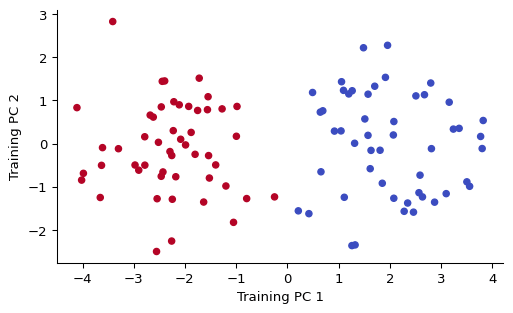

In [2]:
rng = np.random.default_rng(17)
p = rng.uniform(0.12, 0.85, 90)
delta = rng.normal(0, 0.075, 90)


def draw(n):
    g = np.arange(n) % 2
    probs = np.clip(p[None, :] + (2 * g[:, None] - 1) * delta, 0.03, 0.97)
    return rng.binomial(2, probs), g


X, y = draw(220)
test, labels = draw(100)
freq = X.mean(0) / 2
sd = np.sqrt(2 * freq * (1 - freq))
keep = sd > 0
standard = lambda z: (z[:, keep] - 2 * freq[keep]) / sd[keep]
model = PCA(4, svd_solver="full").fit(standard(X))
z = model.transform(standard(test))
print("Training variance fractions", model.explained_variance_ratio_.round(3))
print("Held-out individuals", len(test))
plt.figure(figsize=(5.5, 3.4))
plt.scatter(*z[:, :2].T, c=labels, cmap="coolwarm", s=22)
plt.xlabel("Training PC 1")
plt.ylabel("Training PC 2")
plt.tight_layout()
plt.show()

## Interpreting the result

A principal component axis can be multiplied by minus one with the same fit. Separation depends on marker selection and the simulated frequency difference.

## Exercise

Set every simulated frequency shift to zero and compare the held-out separation.

## References

[Patterson, Price and Reich, population structure and eigenanalysis (2006)](https://doi.org/10.1371/journal.pgen.0020190)